In [1]:
import xarray as xr 
import numpy as np
from glob import glob
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from matplotlib import cm
import matplotlib.pyplot as plt

from cmcrameri import cm as cmcra
import plotting_utils
plotting_utils.mk_binary_alpha()

In [2]:
def get_files(path_source, exp, folders, grid):
    """Return sorted file paths for the given experiment, folders, and grid."""
    path = Path(path_source) / exp

    files = sorted(
        f
        for folder in folders
        for f in (path / folder).glob(f"*1y*{grid}.nc")
    )
    return files


In [3]:
# importing processed dataset
path_source = Path('../steady_out/') 

exp = 'TEMP'
ds_NS = xr.open_dataset(path_source / f"{exp}.nc")
ds_NS_steady = ds_NS.sel(T0=1)

exp = 'FSLIP'
ds_FS_steady = xr.open_dataset(path_source / f"{exp}.nc")


path_source = Path('../monthly_out/')

exp = 'FSLIP_m'
ds_FS_monthly = xr.open_dataset(path_source / f"{exp}.nc")

In [4]:
# Importing raw dataset

path_source = Path('../raw_yearly_out/') 
exp =  'FSLIP_wtc'


years = ["0108", "0109", "0110"]

# Import experiment
dsT_FS, dsU_FS, dsV_FS, dsW_FS = [
    xr.open_mfdataset(
        get_files(path_source, exp, years, grid),
        combine="by_coords",
    )
    for grid in ["T", "U", "V", "W"]
]

print(f"Imported {exp}")


Imported FSLIP_wtc


In [5]:
# Useful functions

def clean_T(ds):
    ds = ds.isel(x=slice(1,127), y=slice(1,27), deptht=slice(0,30))
    return ds

def get_u_depth_mean_on_T(ds):
    U = ds.vozocrtx.where(ds.vozocrtx != 0) #mask over land
    U = U.mean(dim='depthu')
    U = (U.values[:,:,1:] + U.values[:,:,:-1])/2
    U = U[:,1:,:]
    return U

def get_v_depth_mean_on_T(ds):
    V = ds.vomecrty.where(ds.vomecrty != 0) #mask over land
    V = V.mean(dim='depthv')
    V = (V.values[:,1:,:] + V.values[:,:-1,:])/2
    V = V[:,:,1:]
    return V

def get_bsf_on_T(BSF):
    bsf = (BSF[1:] + BSF[:-1])/2
    return bsf


In [6]:
# define grid coordinates

# meridional
x_T = np.arange(1,251+1,2)
x_U = np.arange(0,252+1,2)

# zonal
y_T = np.arange(1,51+1,2)
y_V = np.arange(0,52+1,2)

# depth
z_T = np.arange(10,590+1,20)
z_W = np.arange(0,600+1,20)

# Basal melt rates

In [7]:
# define lists
sfx_list = np.arange(0, 0.1+0.001, 0.005) # g/m^2/s

colors_plot =  ['tab:blue','tab:orange']

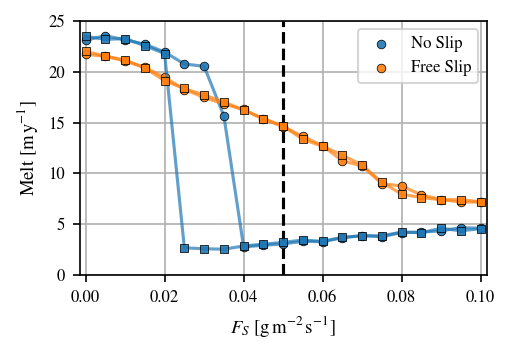

In [8]:
datasets = [
    (ds_NS_steady.melt_0D, colors_plot[0], "No Slip"),
    (ds_FS_steady.melt_0D, colors_plot[1], "Free Slip")
]

plt.figure(figsize=(3.5,2.2),dpi=150)

plt.vlines([0.05],0,25,colors='black', linestyle='dashed')

for i, marker in enumerate(['o', 's']):
    for data, color, label in datasets:

        y = data.isel(transition=i).values

        plt.plot(
            sfx_list, y,
            color=color, alpha=0.7
        )

        plt.scatter(
            sfx_list, y,
            marker=marker,
            edgecolors='black',
            facecolors=color,
            lw=0.4, s=17,
            alpha=0.9, zorder=2,
            label=label if i == 0 else None
        )



plt.xlabel(r'$F_S$ [$\mathrm{g\,m^{-2}\,s^{-1}}$]') 
plt.ylabel(r'Melt [$\mathrm{m\,y^{-1}}$]')


plt.xlim(0-0.0015,0.1+0.0015)
plt.ylim(0, 25)

#plt.yscale('log')

plt.grid()

plt.legend()

plt.savefig('./Figure10/FSLIP_melt.pdf', format='pdf', bbox_inches='tight')

plt.show()

# dzT

In [14]:
# define lists

time_list = np.linspace(0,210,210*12) # years

depth_list = np.arange(20, 580+1, 20) # m

dzT_resto = (1 - (-1.9))/600 # °C/m

ds_FS_monthly.sel(transition="wtc").dzT

<xarray.DataArray 'dzT' (time: 2520, depth: 29)> Size: 585kB
array([[ 0.004245,  0.004268,  0.004576, ...,  0.004898,  0.00494 ,  0.004103],
       [ 0.00351 ,  0.00335 ,  0.003798, ...,  0.004724,  0.004357,  0.002766],
       [ 0.006084,  0.001353,  0.001496, ...,  0.004425,  0.003768,  0.001996],
       ...,
       [ 0.000646,  0.001449,  0.001629, ...,  0.000648,  0.000514,  0.001135],
       [ 0.00066 ,  0.00157 ,  0.001847, ...,  0.000713,  0.000732,  0.002351],
       [ 0.000626,  0.001394,  0.001734, ...,  0.000637,  0.000454, -0.000127]])
Coordinates:
    transition  <U3 12B 'wtc'
  * time        (time) float64 20kB 0.0 0.08337 0.1667 ... 209.8 209.9 210.0
  * depth       (depth) int64 232B 20 40 60 80 100 120 ... 500 520 540 560 580
Attributes:
    descr:    Mean vertical temperature gradient under the polynya [°C/m]

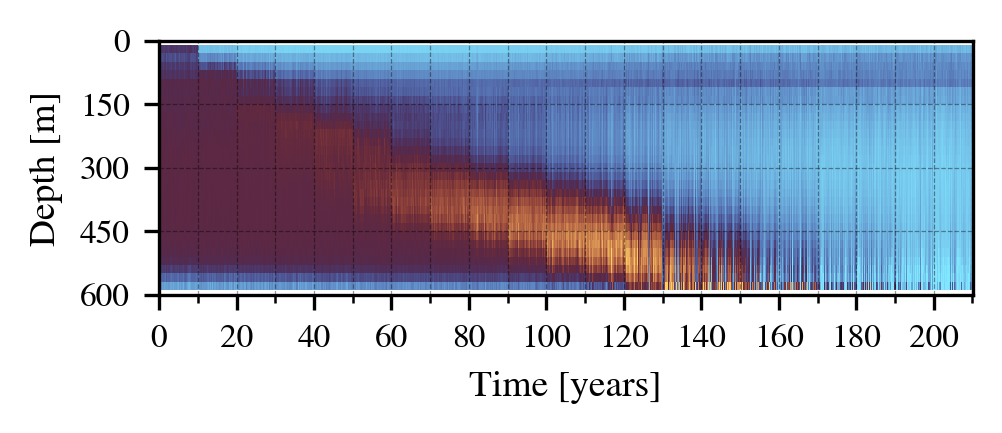

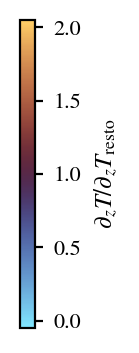

In [17]:
TT, ZZ = np.meshgrid(time_list,depth_list)

dzT = ds_FS_monthly.dzT.sel(transition="wtc")

fig = plt.figure(figsize=(3.5,1.1),dpi=300)
ax = plt.gca()


vmin = -0.05
vmax = 2.05
norm = colors.Normalize(vmin=vmin, vmax=vmax,)
plotting = {'vmin':vmin, 'vmax':vmax, 'cmap':cmcra.managua_r,}
cont_dzT = ax.pcolormesh(TT,ZZ,(dzT/dzT_resto).T, **plotting)


from matplotlib.ticker import MultipleLocator
ax.xaxis.set_major_locator(MultipleLocator(20)) # Major ticks → every 20 (these get labels)
ax.xaxis.set_minor_locator(MultipleLocator(10)) # Minor ticks → every 10 (grid only)

ax.set_yticks(np.arange(0,600+1,150))

ax.invert_yaxis()

ax.set_ylabel('Depth [m]')
ax.set_xlabel('Time [years]')



ax.grid(which='major', lw=0.3, c='black', alpha=0.4, ls='dashed')
ax.grid(which='minor', lw=0.3, c='black', alpha=0.4, ls='dashed')


plt.savefig(f'./Figure10/FSLIP_dzT_monthly_avg_over_polynya.png', format='png', dpi=300, bbox_inches='tight')

plt.show()




# colorbar
fig_cb, ax_cb = plt.subplots(figsize=(5.5, 2),dpi=200)  # taller than wide

cbar = fig_cb.colorbar(
    cont_dzT,
    ax=ax_cb,
    fraction=0.15,   # controls width (smaller = thinner)
    aspect=20       # controls length/thickness ratio
)

ax_cb.remove()

cbar.set_label(r'$\partial_zT/\partial_zT_\mathrm{resto}$', fontsize=9)
cbar.ax.tick_params(labelsize=8, width=0.8, length=3)

plt.savefig(f'./Figure10/dzT_monthly_cbar.pdf', format='pdf', bbox_inches='tight')
plt.show()

# BSF

In [60]:
def plot_bsf_uv(x_T, y_T, bsf, bsf_cav, U, V, plotting_bsf, plotting_bsf_cav, plotting_quiver, quiv_gap, quiv_thresh):
    """
    Plot the basal shear stress (BSF) and depth-averaged velocity (U, V) fields.
    Parameters:
    x_T : array-like
        x-coordinates of the T-grid.
    y_T : array-like
        y-coordinates of the T-grid.
    bsf : array-like
        Barotropic stream function field.
    bsf_cav : array-like
        Barotropic stream function field in the cavity region.
    U : array-like
        Depth-averaged U velocity component.
    V : array-like
        Depth-averaged V velocity component.
    plotting_bsf : dict
        Plotting parameters for the BSF field.
    plotting_bsf_cav : dict
        Plotting parameters for the BSF cavity field.
    plotting_quiver : dict
        Plotting parameters for the quiver plot.
    quiv_gap : int
        Gap between quiver arrows.
    quiv_thresh : float
        Threshold for plotting quiver arrows.
    """

    fig, ax = plt.subplots(figsize=(5.5, 1.1), dpi=200)

    X_bsf, Y_bsf = np.meshgrid(x_T[:-1], y_T[:-1])
    contour_bsf = ax.contourf(X_bsf, Y_bsf, bsf, **plotting_bsf)
    ax.contour(X_bsf, Y_bsf, bsf, levels=[0], colors='white', linewidths=1, zorder=2)

    X_bsf_cav = X_bsf[:,:51]
    Y_bsf_cav = Y_bsf[:,:51]
    cont_bsf_cav = ax.contourf(X_bsf_cav, Y_bsf_cav, bsf_cav, **plotting_bsf_cav)
    ax.contour(X_bsf_cav, Y_bsf_cav, bsf_cav, levels=[0], colors='white', linewidths=1, zorder=2)

    X_uv, Y_uv = np.meshgrid(x_T[:], y_T[:])

    s = quiv_gap
    offset1 = 3
    offset2 = 1
    idx = np.zeros(U.shape, dtype=bool)
    idx[offset1::s, offset1::s] = True
    idx[offset2::s, offset2::s] = True

    ax.quiver(
        X_uv[idx], Y_uv[idx],
        U[idx], V[idx],
        (np.hypot(U, V) >= quiv_thresh)[idx].astype(float),
        **plotting_quiver,
        zorder=2
    )

    ax.set_yticks(ticks=np.arange(0, 51, 25))
    ax.set_ylim(0,50)
    ax.set_xlim(0,250)
    ax.vlines([100, 120], ymin=0, ymax=51, colors='black', linestyles='dotted',linewidths=1)
    ax.vlines([240], ymin=0, ymax=51, colors='black', linestyles='dashed', linewidths=1)
    ax.set_aspect('equal')
    ax.set_xlabel('x [km]')
    ax.set_ylabel('y [km]')
    plt.quiver(50, 2, 0.1, 0, color='red', zorder=2, **plotting_quiver,)
    plt.text(46, 4, r'10 $\mathrm{cm \, s^{-1}}$', color='red', fontsize=6)


    ax.scatter(X_uv[3,55],Y_uv[2,55], c='red', marker='x', s=15)
    ax.scatter(X_uv[21,55],Y_uv[22,55], c='red', marker='x', s=15)

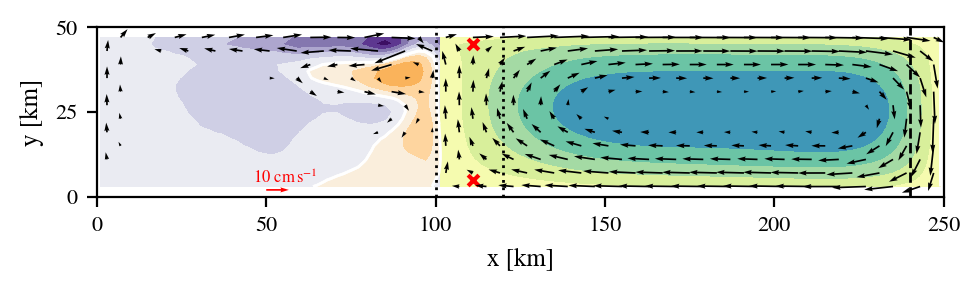

In [65]:
ds = ds_FS_steady.sel(transition="wtc", Fs=0.05)
dsU = dsU_FS
dsV = dsV_FS

# BSF open ocean
bsf = ds.BSF.values
bsf = get_bsf_on_T(bsf)
bsf[:,:50] = np.nan * np.ones((25,50)) # masking cavity

vmin = -1.5
vmax = 1.5
levels = np.linspace(vmin,vmax,13)
norm = colors.Normalize(vmin=vmin, vmax=vmax,)
plotting_bsf = {'vmin':vmin, 'vmax':vmax, 'cmap':cm.Spectral_r, 'levels':levels, 'norm':norm, 'extend':'both'}


# BSF cavity
bsf = ds.BSF.values
bsf = get_bsf_on_T(bsf)
bsf_cav = bsf[:, :51] # taking the cavity part of the BSF

vmin = -0.3
vmax = 0.3
levels = np.linspace(vmin,vmax,13)
norm = colors.Normalize(vmin=vmin, vmax=vmax,)
plotting_bsf_cav = {'vmin':vmin, 'vmax':vmax, 'cmap':cm.PuOr_r, 'levels':levels, 'norm':norm, 'extend':'both'}


# U and V averaged on depth

U = get_u_depth_mean_on_T(dsU)
V = get_v_depth_mean_on_T(dsV)

U = np.mean(U, axis=0)
V = np.mean(V, axis=0)

plotting_quiver = {'scale':0.015, 'cmap':'binary_alpha', 'width':0.5, 'units':'xy', 'pivot':'tail'}
quiv_gap, quiv_thresh = (4,0.02) # (gap, threshold)


plot_bsf_uv(x_T, y_T, bsf, bsf_cav, U, V, plotting_bsf, plotting_bsf_cav, plotting_quiver, quiv_gap, quiv_thresh)
plt.savefig('./Figure10/FSLIP_bsf.pdf',format='pdf', bbox_inches='tight')
plt.show()


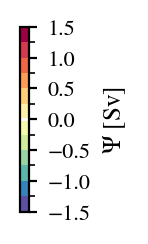

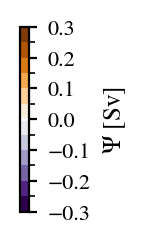

In [63]:
# Generate color bar

# open ocean

fig_cb, ax_cb = plt.subplots(figsize=(5.5, 1.2), dpi=200)  # taller than wide

# Define a generic mappable
levels = np.linspace(-1.5,1.5,13)
mappable = matplotlib.cm.ScalarMappable(
    norm=matplotlib.colors.BoundaryNorm(levels, ncolors=256),
    cmap=cm.Spectral_r
)


cbar = fig_cb.colorbar(
    mappable,
    ax=ax_cb,
    fraction=0.15,   # controls width (smaller = thinner)
    aspect=20       # controls length/thickness ratio
)

cbar.ax.axhline(0, color='white', linewidth=1,)

ax_cb.remove()

cbar.set_ticks([-1.5, -1, -0.5, 0, 0.5,1,1.5])

cbar.set_label(r'$\Psi$ [Sv]', fontsize=9)
cbar.ax.tick_params(labelsize=8, width=0.8, length=3)

plt.savefig('./Figure10/bsf_bar.pdf',format='pdf', bbox_inches='tight')
plt.show()




# Cavity

fig_cb, ax_cb = plt.subplots(figsize=(5.5, 1.2), dpi=200)  # taller than wide

# Define a generic mappable
levels = np.linspace(-0.3,0.3,13)
mappable = matplotlib.cm.ScalarMappable(
    norm=matplotlib.colors.BoundaryNorm(levels, ncolors=256),
    cmap=cm.PuOr_r
)


cbar = fig_cb.colorbar(
    mappable,
    ax=ax_cb,
    fraction=0.15,   # controls width (smaller = thinner)
    aspect=20       # controls length/thickness ratio
)

cbar.ax.axhline(0, color='white', linewidth=1,)

ax_cb.remove()

cbar.set_label(r'$\Psi$ [Sv]', fontsize=9)
cbar.ax.tick_params(labelsize=8, width=0.8, length=3)

plt.savefig('./Figure10/bsf_cav_bar.pdf',format='pdf', bbox_inches='tight')
plt.show()



# $y \times z$ temperature slice 

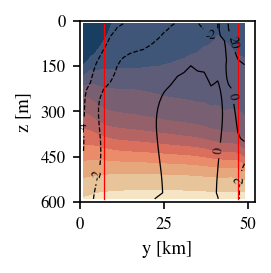

In [ ]:
temp_slice = dsT_FS.votemper.mean(dim='time_counter').isel(x=55)
temp_slice = temp_slice.where(temp_slice != 0).values[:-1,1:]

vmin = -2
vmax = 1
levels = np.linspace(vmin,vmax,13)
norm = colors.Normalize(vmin=vmin, vmax=vmax,)
plotting_temp = {'vmin':vmin, 'vmax':vmax, 'cmap':cmcra.lipari , 'levels':levels, 'norm':norm,}



u_slice = dsU_FS.vozocrtx.mean(dim='time_counter').sel(x=55)
u_slice = u_slice.where(u_slice != 0).values[:-1,1:]

color = 'k'
linewidths=0.6
alpha=1
levels= np.array([-0.04,-0.02,0,0.2])*100
plotting_u = {'levels':levels, 'colors':color, 'linewidths':linewidths, 'alpha':alpha}



YY, ZZ = np.meshgrid(y_T, z_T)

fig = plt.figure(figsize=(1.5,1.57), dpi=150)
ax = plt.gca()

cont_temp = ax.contourf(YY, ZZ, temp_slice, **plotting_temp)

cont_uu = ax.contour(YY,ZZ,u_slice*100, **plotting_u)
ax.clabel(cont_uu, inline=True, fontsize=6, fmt='%1.0f', use_clabeltext=True)

ax.plot(YY[:,3],ZZ[:,3], c='red', lw=0.6,)
ax.plot(YY[:,23],ZZ[:,23], c='red', lw=0.6,)
        
ax.set_xlabel('y [km]')
ax.set_ylabel('z [m]')
        
ax.invert_yaxis()

ax.set_yticks(np.arange(0,600+1,150))

ax.set_ylim(600,0)
ax.set_xlim(0,52)

ax.set_xticks(np.arange(0,50+1,25))

plt.savefig('./Figure10/temp_yz.pdf',format='pdf', bbox_inches='tight')

plt.show()

C:\Users\User\AppData\Local\Temp\ipykernel_19668\144920562.py:5: UserWarning: Adding colorbar to a different Figure <Figure size 225x235.5 with 1 Axes> than <Figure size 825x180 with 2 Axes> which fig.colorbar is called on.
  cbar = fig_cb.colorbar(


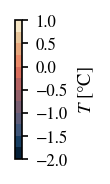

In [105]:
# make colorbar

fig_cb, ax_cb = plt.subplots(figsize=(5.5, 1.2),dpi=150)

cbar = fig_cb.colorbar(
    cont_temp,
    ax=ax_cb,
    fraction=0.15,   # controls width (smaller = thinner)
    aspect=20       # controls length/thickness ratio
)

ax_cb.remove()

cbar.set_label(r'$T$ [°C]', fontsize=9)
cbar.ax.tick_params(labelsize=8, width=0.8, length=3)


plt.savefig('./Figure10/cbar_temp.pdf',format='pdf', bbox_inches='tight')

plt.show()